In [99]:
import pyvis.network as vis
import pandas as pd
import numpy as np

df = pd.read_csv('/home/lucca/Documents/Atividades escolares/impatech/Projeto portinari/Projeto-Portinari/Data/Poemas/Palavras.csv',index_col=0)

In [100]:
words = set(df.sort_values(by='frequencia',ascending=False).head(15).index)
#escolhendo as palavras que mais aparecem mas não possuem algum significado interessante apenas para deixar o grafo mais leve
print(words)
words.remove('não')
print(words)

{'da', 'os', 'do', 'e', 'a', 'se', 'as', 'para', 'que', 'de', 'dos', 'no', 'o', 'não', 'em'}
{'da', 'os', 'do', 'e', 'a', 'se', 'as', 'para', 'que', 'de', 'dos', 'no', 'o', 'em'}


In [101]:
df_filtrado = df.drop(
    index=df.index.intersection(words),
    columns=df.columns.intersection(words),
)

In [114]:
net = vis.Network(height='750px', width='100%')

net.toggle_physics(False)

In [115]:
for palavra in df.columns[:-1]:
    net.add_node(n_id=palavra,value = df.loc[palavra,palavra])

In [116]:
opcoes_interacao = """
{
  "interaction": {
    "hover": true,
    "hoverConnectedEdges": true,
    "selectConnectedEdges": true,
    "dragNodes": false
  },
  "edges": {
    "color": {
      "color": "rgba(150, 150, 150, 0.2)",
      "hover": "#ff4d4d",
      "highlight": "#ff0000",
      "inherit": false
    },
    "width": 1.5,
    "hoverWidth": 2.5
  },
  "physics": {
    "solver": "forceAtlas2Based",
    "forceAtlas2Based": {
      "gravitationalConstant": -50,
      "centralGravity": 0.01,
      "springLength": 100,
      "springConstant": 0.08,
      "damping": 1.0
    },
    "minVelocity": 0.0,
    "stabilization": {
      "enabled": true,
      "iterations": 500,
      "fit": true
    }
  }
}
"""
net.set_options(opcoes_interacao)

Grafo teste

In [117]:
palavras = df_filtrado.columns[:-1].tolist()

matriz = df_filtrado.iloc[:,:-1].to_numpy()

matriz_superior = np.triu(matriz, k=1)
linhas, colunas = np.where(matriz_superior > 0)
print(len(colunas))

for r, c in zip(linhas[:100000], colunas[:100000]):
    valor = int(matriz_superior[r, c])
    net.add_edge(source=palavras[r], to=palavras[c], value=valor)

212675


grafo completo

In [ ]:
palavras = df_filtrado.columns[:-1].tolist()

matriz = df_filtrado.iloc[:,:-1].to_numpy()

matriz_superior = np.triu(matriz, k=1)

linhas, colunas = np.where(matriz_superior > 0)

for r, c in zip(linhas, colunas):
    valor = int(matriz_superior[r, c])
    net.add_edge(source=palavras[r], to=palavras[c], value=valor)

In [118]:
net.write_html('grafo_interativo.html')

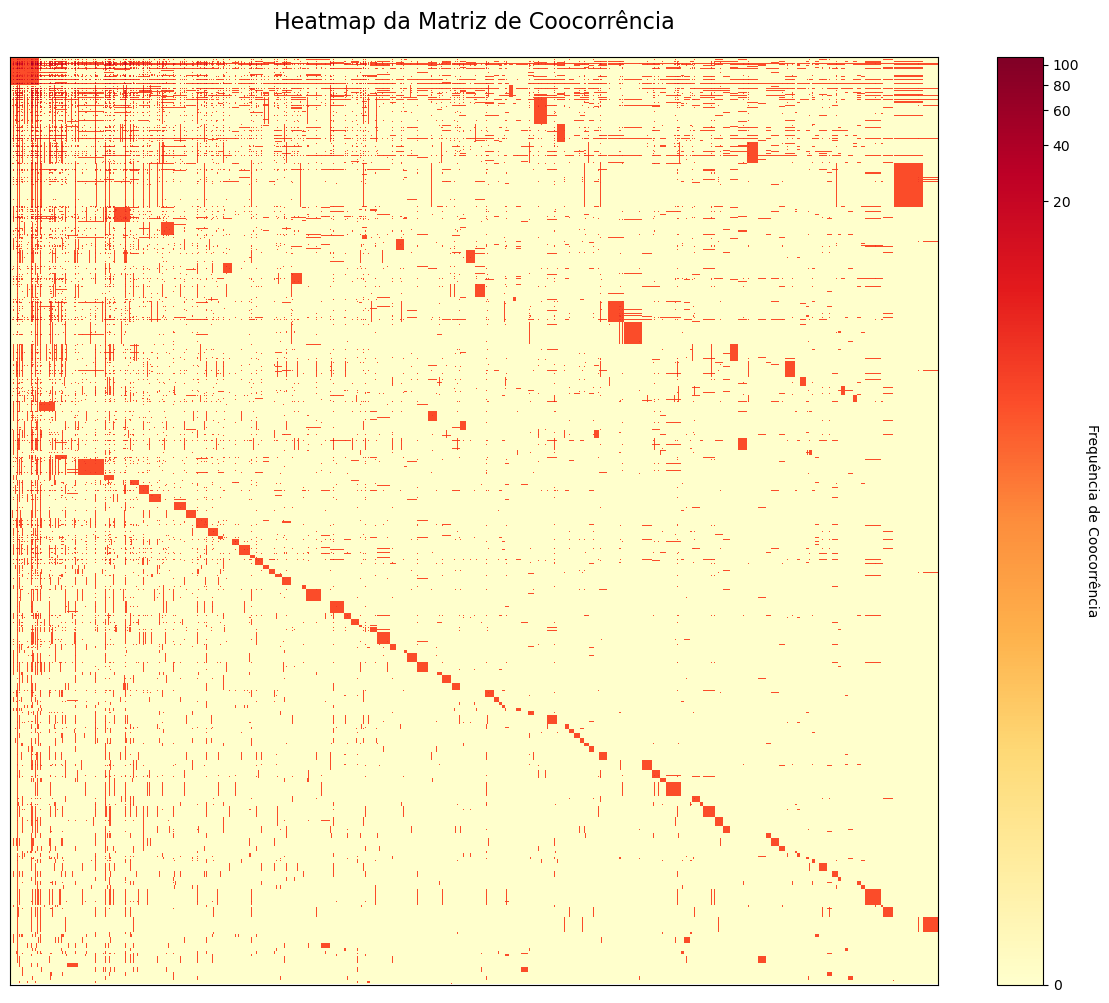

In [98]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

fig, ax = plt.subplots(figsize=(12, 10))

norma = mcolors.PowerNorm(gamma=0.1)


heatmap = ax.imshow(df, cmap='YlOrRd', interpolation='nearest', norm = norma)

# adiciona a barra de cores lateral
cbar = ax.figure.colorbar(heatmap, ax=ax)
cbar.ax.set_ylabel("Frequência de Coocorrência", rotation=-90, va="bottom")

ax.set_xticks([])
ax.set_yticks([])

# Titulo
ax.set_title("Heatmap da Matriz de Coocorrência", fontsize=16, pad=20)
fig.tight_layout() # Garante que as palavras nas bordas não sejam cortadas da imagem

plt.show()